## Task-1 Load & Explore the Dataset

In [69]:
#load the dataset
import pandas as pd
import numpy as np
df=pd.read_csv('output.csv')

In [70]:
#check columns
df.columns

Index([' Review', 'Liked'], dtype='object')

In [71]:
df['Liked'].value_counts()

Liked
1    500
0    500
Name: count, dtype: int64

In [72]:
#Display
#First 10 rows
df.head(10)

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1
5,Now I am getting angry and I want my damn pho.,0
6,Honeslty it didn't taste THAT fresh.),0
7,The potatoes were like rubber and you could te...,0
8,The fries were great too.,1
9,A great touch.,1


In [73]:
#Number of samples per class
df['Liked'].value_counts()#Balanced dataset

Liked
1    500
0    500
Name: count, dtype: int64

In [74]:
#Missing values
df.isnull().sum()#no null values

 Review    0
Liked      0
dtype: int64

In [75]:
print(df.columns.tolist())

[' Review', 'Liked']


In [76]:
#Remove unwanted spaces
df.columns=df.columns.str.strip()

In [77]:
#Review text length distribution 
df['Review_Length'] = df['Review'].astype(str).apply(len)

In [78]:
print(df[['Review','Review_Length']].head(10))

                                              Review  Review_Length
0                           Wow... Loved this place.             24
1                                 Crust is not good.             18
2          Not tasty and the texture was just nasty.             41
3  Stopped by during the late May bank holiday of...             87
4  The selection on the menu was great and so wer...             59
5     Now I am getting angry and I want my damn pho.             46
6              Honeslty it didn't taste THAT fresh.)             37
7  The potatoes were like rubber and you could te...            111
8                          The fries were great too.             25
9                                     A great touch.             14


## Task-2 Clean & Preprocess the Text

In [117]:
#Expanding contractions
!pip install contractions

In [118]:
import contractions
words = [
    "didn't",
    "isn't",
    "aren't",
    "don't",
    "doesn't",
    "can't",
    "won't",
    "I'm",
    "I've",
    "you're",
    "they've",
    "it's"
]
for word in words:
    print(word, "→", contractions.fix(word))

didn't → did not
isn't → is not
aren't → are not
don't → do not
doesn't → does not
can't → cannot
won't → will not
I'm → I am
I've → I have
you're → you are
they've → they have
it's → it is


In [132]:
df['Clean_Review'] = df['Review'].fillna('').apply(contractions.fix)

In [133]:
df['Clean_Review'] = df['Review'].apply(
    lambda x: contractions.fix(str(x))
)
print(df['Clean_Review'].iloc[6])
print("Original:", df['Review'].iloc[6])
print("Expanded:", df['Clean_Review'].iloc[6])

Honeslty it did not taste THAT fresh.)
Original: Honeslty it didn't taste THAT fresh.)
Expanded: Honeslty it did not taste THAT fresh.)


In [137]:
#convert all text to lowercase
df['Clean_Review']=df['Clean_Review'].str.lower()

In [138]:
#Remove punctuation, numbers and special characters 
import re
df['Clean_Review']=df['Clean_Review'].apply(lambda x: re.sub(r'[^a-zA-Z\s]','',str(x)))

In [139]:
df[['Review', 'Clean_Review']].head(10)

,Review,Clean_Review
0,Wow... Loved this place.,wow loved this place
1,Crust is not good.,crust is not good
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty
3,Stopped by during the late May bank holiday of...,stopped by during the late may bank holiday of...
4,The selection on the menu was great and so wer...,the selection on the menu was great and so wer...
5,Now I am getting angry and I want my damn pho.,now i am getting angry and i want my damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty it did not taste that fresh
7,The potatoes were like rubber and you could te...,the potatoes were like rubber and you could te...
8,The fries were great too.,the fries were great too
9,A great touch.,a great touch


In [140]:
#checking whether they are actual dots or characters
print(repr(df['Review'].iloc[4]))
print(repr(df['Clean_Review'].iloc[4]))

'The selection on the menu was great and so were the prices.'
'the selection on the menu was great and so were the prices'


In [141]:
#Remove Extra spaces
df['Clean_Review']=df['Clean_Review'].apply(lambda x:re.sub(r'\s+',' ',x).strip())

In [142]:
#Remove Stopwords
import nltk
from nltk.corpus import stopwords
stop_words=set(stopwords.words('english'))
print(sorted(stop_words))
stop_words = stop_words - {'not', 'no', 'nor'}

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", "he's", 'her', 'here', 'hers', 'herself', 'him', 'himself', 'his', 'how', 'i', "i'd", "i'll", "i'm", "i've", 'if', 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [143]:
df['Clean_Review'] = df['Clean_Review'].apply(
    lambda x: ' '.join(
        word for word in x.split()
        if word not in stop_words))

In [144]:
print(df[['Review', 'Clean_Review']].head(10))

                                              Review  \
0                           Wow... Loved this place.   
1                                 Crust is not good.   
2          Not tasty and the texture was just nasty.   
3  Stopped by during the late May bank holiday of...   
4  The selection on the menu was great and so wer...   
5     Now I am getting angry and I want my damn pho.   
6              Honeslty it didn't taste THAT fresh.)   
7  The potatoes were like rubber and you could te...   
8                          The fries were great too.   
9                                     A great touch.   

                                        Clean_Review  
0                                    wow loved place  
1                                     crust not good  
2                            not tasty texture nasty  
3  stopped late may bank holiday rick steve recom...  
4                        selection menu great prices  
5                        getting angry want damn pho 

In [145]:
#Lemmatization
import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Niharika\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Niharika\AppData\Roaming\nltk_data...
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Niharika\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [146]:
from nltk.stem import WordNetLemmatizer
lemmatizer=WordNetLemmatizer()

In [149]:
#applying lemmatization
df['Clean_Review']=df['Clean_Review'].apply(
    lambda x: ' '.join(lemmatizer.lemmatize(word) for word in x.split()))

In [150]:
#inspecting before and after lemmatization
print(df[['Review','Clean_Review']].head(10))

                                              Review  \
0                           Wow... Loved this place.   
1                                 Crust is not good.   
2          Not tasty and the texture was just nasty.   
3  Stopped by during the late May bank holiday of...   
4  The selection on the menu was great and so wer...   
5     Now I am getting angry and I want my damn pho.   
6              Honeslty it didn't taste THAT fresh.)   
7  The potatoes were like rubber and you could te...   
8                          The fries were great too.   
9                                     A great touch.   

                                        Clean_Review  
0                                    wow loved place  
1                                     crust not good  
2                            not tasty texture nasty  
3  stopped late may bank holiday rick steve recom...  
4                         selection menu great price  
5                        getting angry want damn pho 

In [151]:
print(df[['Review', 'Clean_Review', 'Liked']].head(10))
print(df['Clean_Review'].isnull().sum())
print(df['Liked'].value_counts())

                                              Review  \
0                           Wow... Loved this place.   
1                                 Crust is not good.   
2          Not tasty and the texture was just nasty.   
3  Stopped by during the late May bank holiday of...   
4  The selection on the menu was great and so wer...   
5     Now I am getting angry and I want my damn pho.   
6              Honeslty it didn't taste THAT fresh.)   
7  The potatoes were like rubber and you could te...   
8                          The fries were great too.   
9                                     A great touch.   

                                        Clean_Review  Liked  
0                                    wow loved place      1  
1                                     crust not good      0  
2                            not tasty texture nasty      0  
3  stopped late may bank holiday rick steve recom...      1  
4                         selection menu great price      1  
5          

## Task-3 Convert Text to Numerical Features

In [175]:
#import both vectorizers
from sklearn.feature_extraction.text import TfidfVectorizer

In [176]:
#create both vectorizers
tfidf=TfidfVectorizer()

In [177]:
#Applying TF-IDF
X_tfidf=tfidf.fit_transform(df['Clean_Review'])

In [178]:
#Checking their shapes
print("TF-IDF:",X_tfidf.shape)

TF-IDF: (1000, 1781)


## Task-4 Train-Test Split 

In [179]:
#import train_test_split
from sklearn.model_selection import train_test_split

In [159]:
#Seperate input and target
y=df['Liked']

In [160]:
#splitting using TF-IDF
X_train_tfidf,X_test_tfidf,y_train,y_test=train_test_split(X_tfidf,y,test_size=0.2,random_state=42)

In [180]:
print("TF-IDF Training:", X_train_tfidf.shape)
print("TF-IDF Testing:", X_test_tfidf.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

TF-IDF Training: (800, 1781)
TF-IDF Testing: (200, 1781)
Training Labels: (800,)
Testing Labels: (200,)


## Task-5 Train Bernoulli Naive Bayes

In [181]:
#import BernoulliNB
from sklearn.naive_bayes import BernoulliNB

In [182]:
#create two models
bnb_tfidf=BernoulliNB()

In [184]:
#Train the TF-IDF model
bnb_tfidf.fit(X_train_tfidf,y_train)

,alpha,1.0
,force_alpha,True
,binarize,0.0
,fit_prior,True
,class_prior,None


## Task-6 Model Evaluation

In [186]:
y_pred_tfidf=bnb_tfidf.predict(X_test_tfidf)

In [188]:
print("TF-IDF Predictions:", y_pred_tfidf[:10])
print("Actual Labels:", y_test.iloc[:10].values)

TF-IDF Predictions: [0 1 1 1 1 1 0 1 0 1]
Actual Labels: [1 1 1 1 1 1 0 1 0 1]


In [189]:
print("TF-IDF Accuracy:", accuracy_score(y_test, y_pred_tfidf))
print("TF-IDF Precision:", precision_score(y_test, y_pred_tfidf))
print("TF-IDF Recall:", recall_score(y_test, y_pred_tfidf))
print("TF-IDF F1 Score:", f1_score(y_test, y_pred_tfidf))

TF-IDF Accuracy: 0.765
TF-IDF Precision: 0.7766990291262136
TF-IDF Recall: 0.7692307692307693
TF-IDF F1 Score: 0.7729468599033816


In [190]:
#Confusion matrix
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred_tfidf)
print(cm)

[[73 23]
 [24 80]]


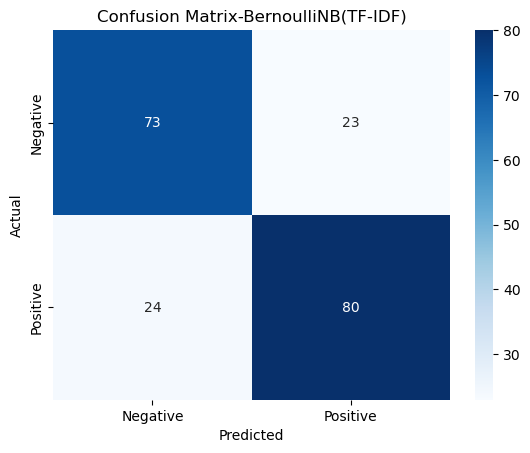

In [191]:
#Visualize the confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Negative','Positive'],yticklabels=['Negative','Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix-BernoulliNB(TF-IDF)')
plt.show()

In [193]:
#Classification Report 
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_tfidf))

              precision    recall  f1-score   support

           0       0.75      0.76      0.76        96
           1       0.78      0.77      0.77       104

    accuracy                           0.77       200
   macro avg       0.76      0.76      0.76       200
weighted avg       0.77      0.77      0.77       200



## Task-7 Predict Sentiment of New Reviews

In [195]:
#creating sample reviews 
new_reviews = ["The food was fantastic!","Worst service ever."]

In [197]:
#Preprocess the new reviews
import re
import contractions
def clean_text(text):
    text=contractions.fix(text)
    text=text.lower()
    text=re.sub(r'[^a-zA-Z\s]','',text)
    text=' '.join(word for word in text.split() if word not in stop_words)
    text=' '.join(lemmatizer.lemmatize(word)
    for word in text.split())
    return text
cleaned_reviews=[clean_text(review) for review in new_reviews]
print(cleaned_reviews)

['food fantastic', 'worst service ever']


In [198]:
#convert text into TF-IDF features 
new_reviews_tfidf=tfidf.transform(cleaned_reviews)

In [200]:
#predict sentiment
predictions=bnb_tfidf.predict(new_reviews_tfidf)
for review,prediction in zip(new_reviews,predictions):
    sentiment='Positive' if prediction==1 else 'Negative'
    print(review,'->',sentiment)

The food was fantastic! -> Positive
Worst service ever. -> Negative


In [202]:
import joblib
joblib.dump(tfidf,'tfidf_vectorizer.pkl')

['tfidf_vectorizer.pkl']

In [203]:
joblib.dump(bnb_tfidf,'sentiment_model.pkl')

['sentiment_model.pkl']

In [204]:
import os
print(os.listdir())

['.anaconda', '.conda', '.continuum', '.copilot', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.python_history', '.virtual_documents', '.vscode', '.vscode-shared', 'Amazon_Fine_Food_Cleaned.csv', 'Amazon_reviews.csv', 'ambitionbox_cleaned.csv', 'ambitionbox_raw_500.csv', 'anaconda3', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Desktop', 'diamonds.csv', 'diamond_model.pkl', 'Documents', 'Downloads', 'Favorites', 'HR Analytics dataset for Probability Task.csv', 'KNN.ipynb', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'Naive Bayes on review classification.ipynb', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{44f55bff-8a20-11f1-b9b3-f6ef4db70b8b}.TM.blf', 'NTUSER.DAT{44f55bff-8a20-11f1-b9b3-f6ef4db70b8b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{44f55bff-8a20-11f1-b9b3-f6ef4db70b8b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'oinstall_tmp', 'OneDrive', 'output.csv', 'PrintHood', '